In [1]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

import matplotlib.pyplot as plt

In [2]:
dataset = load_diabetes(scaled=False)

In [3]:
X_raw = dataset.data
X = np.column_stack([np.ones(X_raw.shape[0]), X_raw])
y = dataset.target

In [4]:
X_, X_test, y_, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67
)

X_train, X_val, y_train, y_val = train_test_split(
    X_, y_, test_size=0.2, random_state=67
)

# LSTQ

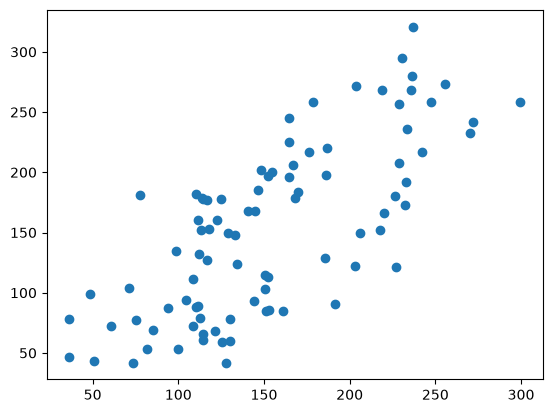

In [5]:
np.linalg.lstsq(X_train, y_train)
m, *_= np.linalg.lstsq(X_train, y_train)
plt.scatter((X_test @ m[:, None]).flatten(), y_test)

# SCIPY

In [6]:
"""
y = x.T @ b + e

distribution = lambda b, sigma: (-1/sigma**2) * np.exp(-(y_n - x_n.T @ b)**2 / (2*sigma**2))
probability_desity = p(y | X.T @ b, sigma**2) = map(mul, distribution)

minimize(probability_desity)
"""

'\ny = x.T @ b + e\n\ndistribution = lambda b, sigma: (-1/sigma**2) * np.exp(-(y_n - x_n.T @ b)**2 / (2*sigma**2))\nprobability_desity = p(y | X.T @ b, sigma**2) = map(mul, distribution)\n\nminimize(probability_desity)\n'

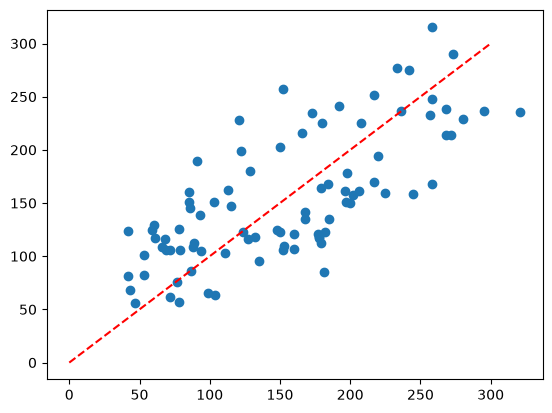

In [7]:
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize
from collections.abc import Callable, Iterable
from numpy.typing import ArrayLike
def normal_dist(X, y, b, sigma):
    return (-1/sigma**2) * np.exp(-(y - X @ b)**2 / (2*sigma**2))

def fun(X, y, b):
    return np.sum(y - X @ b)**2

def rss(beta, X, y):
    return mean_squared_error(y_true=y, y_pred=X@beta)

def rss_explicit(beta, X, y):
    n = X.shape[0]
    rss = (y - X @ beta).T @ (y - X @ beta) / n
    return rss
# result = minimize(
#     fun=rss,                       # Co minimalizujemy?
#     x0=np.zeros(X.shape[1]),      # Skąd startujemy?
#     args=(X, y),                  # Dane przekazywane do RSS
#     jac=rss_gradient,             # Jak obliczyć gradient?
#     method="BFGS",                # Jak szukać minimum?
# )

def scipy_beta(fun: Callable, x0: ArrayLike, args: Iterable, method: str="Powell"):
    minimized = minimize(
        fun=fun,
        x0=x0,
        args=args,
        method=method,
    )
    return minimized.x


beta_estimated = scipy_beta(
        fun=rss_explicit, 
        x0=np.zeros(X_train.shape[1]),
        args=(X_train, y_train),
)


plt.scatter(y_test, X_test @ beta_estimated)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

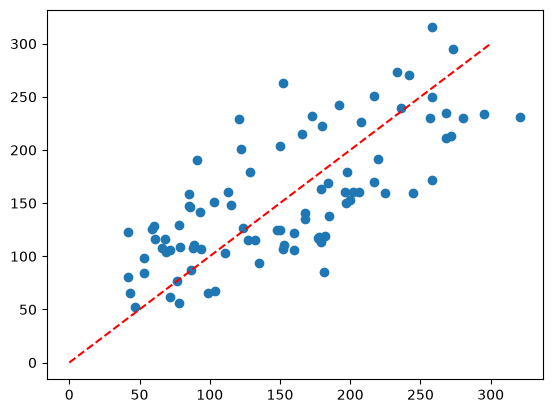

In [8]:
from scipy.stats import norm

def negative_gaussian_log_likelihood(beta, X, y, sigma):
    mu = X @ beta
    return -np.sum(norm.logpdf(y, loc=mu, scale=sigma))

beta_estimated_log_gaussian = scipy_beta(
        fun=negative_gaussian_log_likelihood, 
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, 1),
)

plt.scatter(y_test, X_test @ beta_estimated_log_gaussian)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

# rige

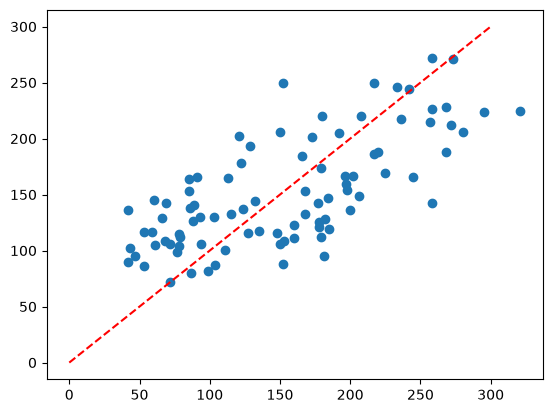

In [9]:
def rigde_loss_function(beta, X, y, lambda_):
    return mean_squared_error(y_true=y, y_pred= X @ beta) + lambda_ * np.linalg.norm(beta[1:])**2

lambda_range = np.logspace(-4, 3, 40)

ridge_scores = []
for lambda_ in lambda_range:
    beta_estimated_ridge = scipy_beta(
        fun=rigde_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, lambda_),
        method="Powell",
    )
    y_beta_estimated_ridge_pred = X_val @ beta_estimated_ridge
    current_score = np.sqrt(mean_squared_error(y_true=y_val, y_pred=y_beta_estimated_ridge_pred))
    ridge_scores.append(current_score)

best_lamda = lambda_range[np.argmin(ridge_scores)]
best_beta_estimated_ridge = scipy_beta(
        fun=rigde_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, best_lamda),
        method="Powell",
    )

plt.scatter(y_test, X_test @ best_beta_estimated_ridge)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

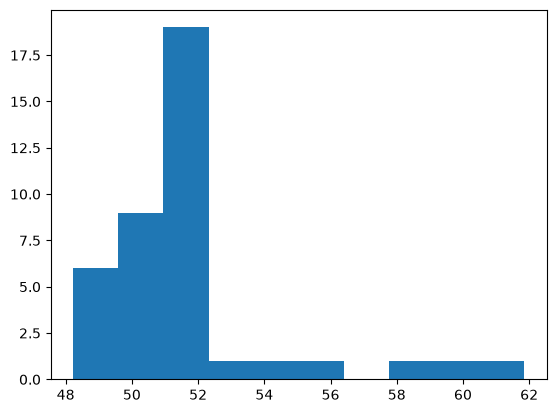

In [10]:
plt.hist(ridge_scores)
plt.show()

# lasso

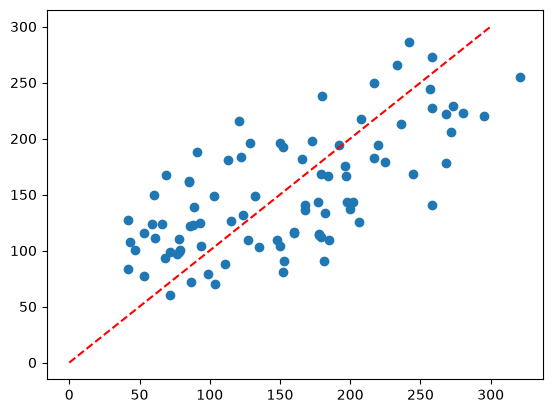

In [11]:
def lasso_loss_function(beta, X, y, lambda_):
    return mean_squared_error(y_true=y, y_pred= X @ beta) + lambda_ * np.sum(np.abs(beta[1:]))


lambda_range = np.logspace(-4, 3, 40)

lasso_scores = []
for lambda_ in lambda_range:
    beta_estimated_lasso = scipy_beta(
        fun=lasso_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, lambda_),
        method="Powell",
    )
    y_beta_estimated_lasso_pred = X_val @ beta_estimated_lasso
    current_score = np.sqrt(mean_squared_error(y_true=y_val, y_pred=y_beta_estimated_lasso_pred))
    lasso_scores.append(current_score)

best_lamda = lambda_range[np.argmin(lasso_scores)]
best_beta_estimated_lasso = scipy_beta(
        fun=lasso_loss_function,
        x0=np.ones(X_train.shape[1]),
        args=(X_train, y_train, best_lamda),
        method="Powell",
    )

plt.scatter(y_test, X_test @ best_beta_estimated_lasso)
plt.plot(np.linspace(0, 300), np.linspace(0, 300), 'r--')

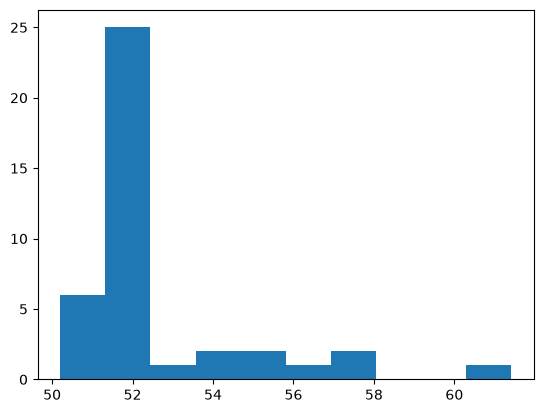

In [12]:
plt.hist(lasso_scores)
plt.show()

# proper pipeline modelling

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import root_mean_squared_error
from scipy import stats

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    dataset.data,
    dataset.target,
    test_size=0.2,
    random_state=67,
)

Best alpha: {'regressor__alpha': np.float64(11.937766417144381), 'regressor__fit_intercept': True}
CV RMSE: 55.86545213563513
Test RMSE: 48.31965415323924


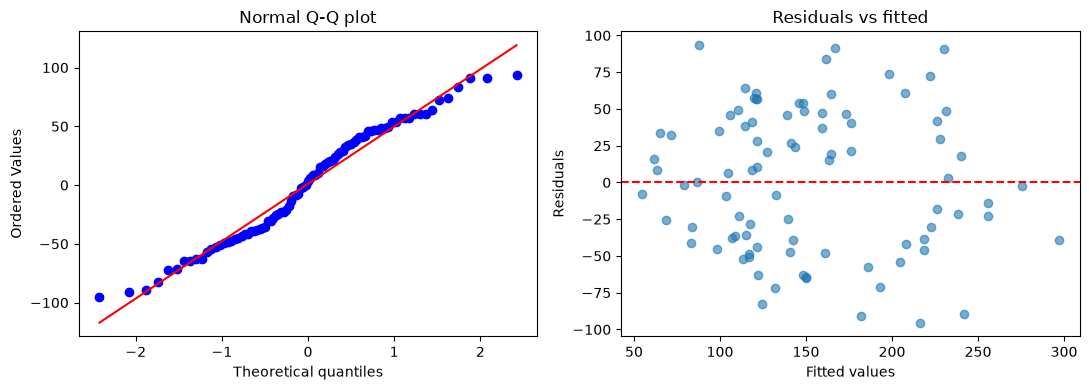

In [15]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge()),
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={
        "regressor__alpha": np.logspace(-4, 2, 40),
        "regressor__fit_intercept": [False, True]
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_)
print("CV RMSE:", -ridge_search.best_score_)

y_pred = ridge_search.predict(X_test)
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

Best alpha: {'regressor__alpha': np.float64(1.4251026703029992)}
CV RMSE: 55.80823620862278
Test RMSE: 48.476724757645016


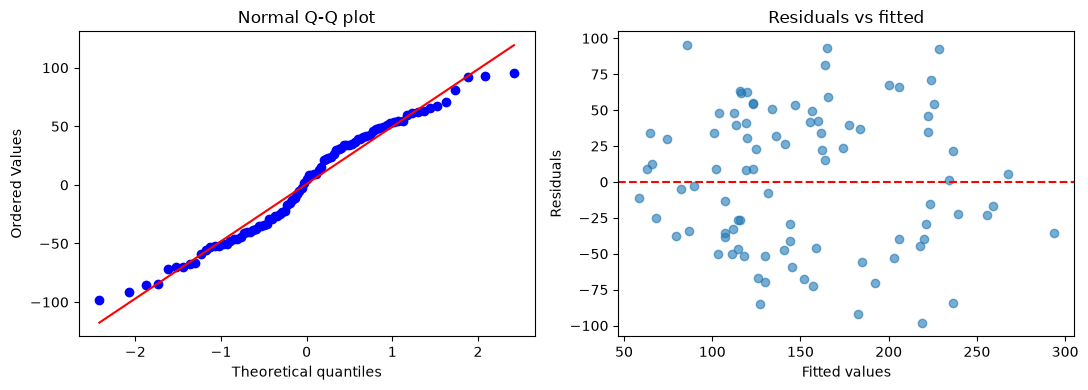

In [16]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso()),
])

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={
        "regressor__alpha": np.logspace(-4, 2, 40),
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

lasso_search.fit(X_train, y_train)

print("Best alpha:", lasso_search.best_params_)
print("CV RMSE:", -lasso_search.best_score_)

y_pred = lasso_search.predict(X_test)
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

Best parameters: {'regressor__alpha': np.float64(1.3738237958832638), 'regressor__l1_ratio': 1.0}
CV RMSE: 55.80664787833907
Test RMSE: 48.46402715912889


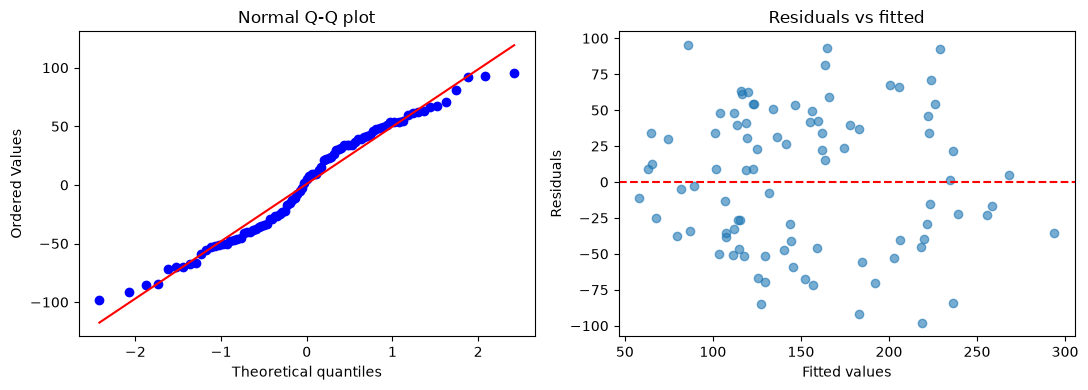

In [17]:
en_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", ElasticNet(max_iter=10000)),
])

en_search = GridSearchCV(
    estimator=en_pipeline,
    param_grid={
        "regressor__alpha": np.logspace(-4, 2, 30),
        "regressor__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

en_search.fit(X_train, y_train)

print("Best parameters:", en_search.best_params_)
print("CV RMSE:", -en_search.best_score_)

y_pred = en_search.predict(X_test)
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

OLS CV RMSE: 55.924110462985865
Test RMSE: 48.03793441202272


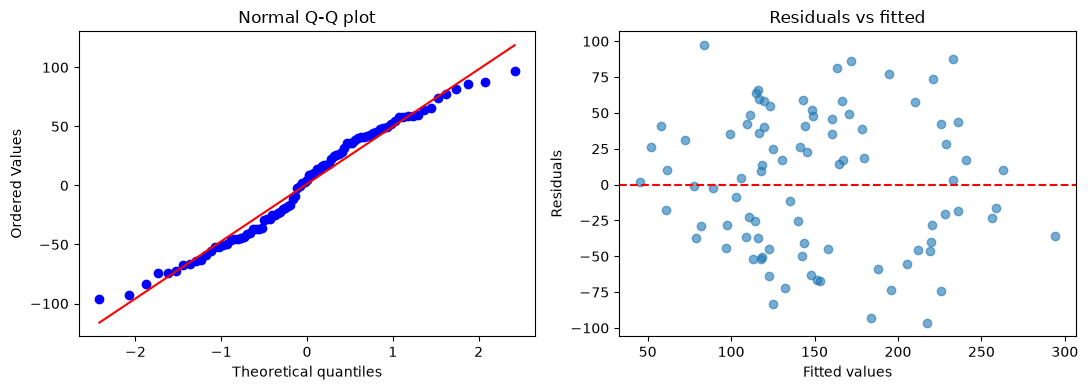

In [18]:
linreg_pipeline = Pipeline(
    [
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression(fit_intercept=True)),
    ]
)

ols_cv = cross_val_score(
    estimator=linreg_pipeline,
    X=X_train,
    y=y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

linreg_pipeline.fit(X_train, y_train)

y_pred = linreg_pipeline.predict(X_test)
print("OLS CV RMSE:", -ols_cv.mean())
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

Best parameters: {'regressor__max_depth': 5, 'regressor__max_features': 1.0, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 300}
CV RMSE: 56.78493835812964
Test RMSE: 49.91123865684805


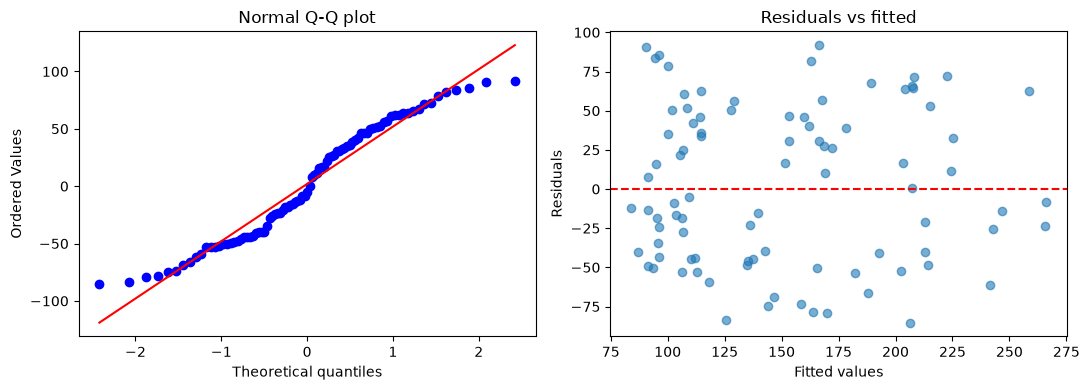

In [21]:
et_pipeline = Pipeline([
    ("regressor", ExtraTreesRegressor(random_state=10)),
])

et_search = GridSearchCV(
    estimator=et_pipeline,
    param_grid={
        "regressor__max_depth": [3, 5],
        "regressor__n_estimators": [10, 20, 50, 100, 300],
        "regressor__min_samples_split": [2, 5, 10],
        "regressor__min_samples_leaf": [1, 2, 5, 10],
        "regressor__max_features": [0.5, 0.8, 1.0],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=10),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

et_search.fit(X_train, y_train)

print("Best parameters:", et_search.best_params_)
print("CV RMSE:", -et_search.best_score_)

y_pred = et_search.predict(X_test)
print("Test RMSE:", root_mean_squared_error(y_test, y_pred))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Normal Q-Q plot")

axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()